In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.integrate import quad
from scipy.stats import binom, norm
# Can get this plotting library from: https://github.com/aabiddanda/arjun_plot
from arjun_plot.utils import *
from adjustText import adjust_text
import polars as pl
from tqdm import tqdm
import sys
sys.path.append('../code/')
from macgregor import * 
from utils import *


plt.rc('font', family='Arial')

%matplotlib inline

In [2]:
# Some small verification steps to check the density of VAF integrates to 1
for age in np.arange(20,100, 5):
    integrand = quad(lambda x: freq_age_density(s=0.00)(x, age), 0, 0.5)[0]
    assert np.isclose(integrand, 1.0)

/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_4714/4183896246.py:3: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda x: freq_age_density(s=0.00)(x, age), 0, 0.5)[0]


In [3]:
tertp_df = pl.read_excel('../data/Table TERTp Age-VAF for Arjun_update 02-06-26 deidentified.xlsx', engine="calamine", read_options={"header_row": 2})
tertp_df.head()

Unique Pt ID,Age at sequencing,TERTp Mutation?,TERTp VAF,Ref_Forward,Ref_Reverse,Alt_F,Alt_R,Total Read Count,De-duplicated total read depth,Ref_F,Ref_R,Alt_F_1,Alt_R_1,Total,Pipeline
str,i64,str,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""523""",30,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""531""",30,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""392""",34,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""526""",34,"""No""",0.0,null,null,null,null,null,null,null,null,null,null,null,null
"""539""",36,"""Yes""",30.3,515,637,233,267,1652,null,null,null,null,null,null,"""Clinical NGS on Research basis…"


In [4]:
# Process data from sheet into numpy arrays for likelihood inference
carrier_df = tertp_df.filter((pl.col('TERTp VAF') > 0) & (pl.col('TERTp VAF') < 50))
noncarrier_df = tertp_df.filter((pl.col('TERTp VAF') == 0))

# Get the carrier information
rs_carriers = np.nan_to_num(carrier_df['Alt_F'].to_numpy()) + np.nan_to_num(carrier_df['Alt_F_1'].to_numpy())
rs_carriers += np.nan_to_num(carrier_df['Alt_R'].to_numpy()) + np.nan_to_num(carrier_df['Alt_R_1'].to_numpy())
ds_carriers = np.nan_to_num(carrier_df['Total Read Count'].to_numpy()) + np.nan_to_num(carrier_df['Total'].to_numpy())
ts_carriers = carrier_df['Age at sequencing'].to_numpy()
assert rs_carriers.size == ts_carriers.size

# Get the non-carrier information
rs_noncarrier = np.zeros(noncarrier_df.shape[0])
ds_noncarrier = np.zeros(noncarrier_df.shape[0])
ts_noncarrier = noncarrier_df['Age at sequencing'].to_numpy()

# concatentate the carrier status
rs_total = np.hstack([rs_carriers, rs_noncarrier])
ds_total = np.hstack([ds_carriers, ds_noncarrier])
ts_total = np.hstack([ts_carriers, ts_noncarrier])

carrier_df.head()

Unique Pt ID,Age at sequencing,TERTp Mutation?,TERTp VAF,Ref_Forward,Ref_Reverse,Alt_F,Alt_R,Total Read Count,De-duplicated total read depth,Ref_F,Ref_R,Alt_F_1,Alt_R_1,Total,Pipeline
str,i64,str,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""539""",36,"""Yes""",30.3,515,637,233,267,1652,null,null,null,null,null,null,"""Clinical NGS on Research basis…"
"""539""",36,"""Yes""",6.6,672,499,56,27,1254,null,null,null,null,null,null,"""Clinical NGS on Research basis…"
"""522""",40,"""Yes""",9.0,1007,1206,95,124,2432,null,null,null,null,null,null,"""Clinical NGS"""
"""391""",45,"""Yes""",6.32,360,277,34,9,680,null,null,null,null,null,null,"""Clinical NGS"""
"""529""",47,"""Yes""",2.36,506,322,15,5,848,null,null,null,null,null,null,"""Clinical NGS"""


In [5]:
%time opt_res = mle_inference(rs_total, ds_total, ts_total)
opt_res

/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:44: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda f: binom.pmf(r2, n=d2, p=f) * x(f, t), 0, 0.5)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:54: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda f: x(f, t), 0.0, f0)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:46: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integrand = quad(lambda f: binom.pmf(r, n=d, p=f) * x(f, t), 0, 0.5)
/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:47: RuntimeWarning: invalid value encountered in log
  return np.log(integrand)


Optimization terminated successfully.
         Current function value: 155.654235
         Iterations: 2
         Function evaluations: 28
CPU times: user 3.95 s, sys: 267 ms, total: 4.22 s
Wall time: 4.13 s


 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 155.65423474602144
       x: [ 3.820e-07  2.421e-01]
     nit: 2
   direc: [[ 1.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00]]
    nfev: 28

In [6]:
# Estimate the confidence interval of mutation and selection parameters for 
# TERTp in mendelian shortTL background 
(s_lower, s_upper) = confint_s(rs_total, ds_total, ts_total, s_hat=opt_res.x[1], mu=opt_res.x[0])
(mu_lower, mu_upper) = confint_mu(rs_total, ds_total, ts_total, mu_hat=opt_res.x[0], s=opt_res.x[1])
print(s_lower, s_upper)
print(mu_lower, mu_upper)

0.21680026211029313 0.27348017014017
2.57821279312216e-07 5.566293926088464e-07


In [7]:
# Estimate mu,s from background individuals in the AoU and UKB cohorts
rv_age_AoU = fit_age_dist_quantiles(method='L-BFGS-B')

def aggregate_AoU_data(fp='../data/AoU_TERTp_Age_VAF.csv', mean_read_depth=32, N=197001, age_rv=None, seed=42):
    """Function to obtain TERTp VAF data from AoU."""
    assert N > 0
    assert mean_read_depth > 0
    assert seed > 0
    
    np.random.seed(seed)
    df = pl.read_csv(fp)
    # Sample the carriers based on calculated VAF alone
    rs_carriers = []
    ds_carriers = []
    ts_carriers = [] 
    for (age, vaf) in zip(df['Sample Age'].to_numpy(), df['TERTp VAF %'].to_numpy()):
        p = vaf / 100
        # NOTE: we should sample the mean depth as well here ...
        r = binom.rvs(n=mean_read_depth, p=p)
        rs_carriers.append(r)
        ds_carriers.append(mean_read_depth)
        ts_carriers.append(age)
    rs_carriers = np.array(rs_carriers)
    ds_carriers = np.array(ds_carriers)
    ts_carriers = np.array(ts_carriers)
    # Sampling ages for the non-carriers ... 
    n_carriers = rs_carriers.size
    assert age_rv is not None
    rs_noncarriers = np.zeros(N - n_carriers)
    ds_noncarriers = np.zeros(N - n_carriers)
    ts_noncarriers = np.round(age_rv.rvs(size = N-n_carriers))
    rs_total = np.hstack([rs_carriers, rs_noncarriers])
    ds_total = np.hstack([ds_carriers, ds_noncarriers])
    ts_total = np.hstack([ts_carriers, ts_noncarriers])
    return (rs_total, ds_total, ts_total)

In [8]:
rs_AoU, ds_AoU, ts_AoU = aggregate_AoU_data(seed=24, age_rv=rv_age_AoU)
%time opt_res_AoU = mle_inference(rs = rs_AoU, ds=ds_AoU, ts=ts_AoU, options={'disp': True})
opt_res_AoU

/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:46: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  integrand = quad(lambda f: binom.pmf(r, n=d, p=f) * x(f, t), 0, 0.5)


Optimization terminated successfully.
         Current function value: 2636.506935
         Iterations: 2
         Function evaluations: 26
CPU times: user 9.46 s, sys: 236 ms, total: 9.69 s
Wall time: 9.52 s


 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2636.5069347659564
       x: [ 3.820e-07  6.130e-02]
     nit: 2
   direc: [[ 1.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00]]
    nfev: 26

In [9]:
(s_AoU_lower, s_AoU_upper) = confint_s(rs = rs_AoU, ds=ds_AoU, ts=ts_AoU, s_hat=opt_res_AoU.x[1], mu=opt_res_AoU.x[0])
(mu_AoU_lower, mu_AoU_upper) = confint_mu(rs = rs_AoU, ds=ds_AoU, ts=ts_AoU, mu_hat=opt_res_AoU.x[0], s=opt_res_AoU.x[1])
print(s_AoU_lower, s_AoU_upper)
print(mu_AoU_lower, mu_AoU_upper)

0.06018626059471011 0.062371556564917885
1.5013623428881154e-08 3.8436991572364624e-07


In [10]:
def aggregate_UKB_data(fp='../data/UKB_TERTp_Age_VAF.csv', mean_read_depth=32, age_fp='../data/UKB_no_heme_nonTERTp_ages.csv', seed=42):
    """Function to obtain TERTp VAF data from AoU."""
    assert mean_read_depth > 0
    assert seed > 0
    
    np.random.seed(seed)
    df = pl.read_csv(fp)
    # Sample the carriers based on calculated VAF alone
    rs_carriers = []
    ds_carriers = []
    ts_carriers = [] 
    for (age, vaf) in zip(df['Age'].to_numpy(), df['TERTp VAF (%)'].to_numpy()):
        p = vaf / 100
        # NOTE: we should sample the mean depth as well here ...
        r = binom.rvs(n=mean_read_depth, p=p)
        rs_carriers.append(r)
        ds_carriers.append(mean_read_depth)
        ts_carriers.append(age)
    rs_carriers = np.array(rs_carriers)
    ds_carriers = np.array(ds_carriers)
    ts_carriers = np.array(ts_carriers)
    # Sampling ages for the non-carriers ... 
    n_carriers = rs_carriers.size
    ages = pl.read_csv(age_fp)
    ts_noncarriers = ages['Age'].to_numpy()
    rs_noncarriers = np.zeros(ts_noncarriers.size)
    ds_noncarriers = np.zeros(ts_noncarriers.size)
    rs_total = np.hstack([rs_carriers, rs_noncarriers])
    ds_total = np.hstack([ds_carriers, ds_noncarriers])
    ts_total = np.hstack([ts_carriers, ts_noncarriers])
    return (rs_total, ds_total, ts_total)

rs_UKB, ds_UKB, ts_UKB = aggregate_UKB_data()

In [11]:
%time opt_res_UKB = mle_inference(rs = rs_UKB, ds=ds_UKB, ts=ts_UKB, f0=0.04, options={'disp': True})
opt_res_UKB

Optimization terminated successfully.
         Current function value: 814.606408
         Iterations: 2
         Function evaluations: 24
CPU times: user 4.12 s, sys: 141 ms, total: 4.26 s
Wall time: 4.13 s


 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 814.6064078802
       x: [ 3.820e-07  8.685e-02]
     nit: 2
   direc: [[ 1.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00]]
    nfev: 24

In [12]:
(s_UKB_lower, s_UKB_upper) = confint_s(rs = rs_UKB, ds=ds_UKB, ts=ts_UKB, s_hat=opt_res_UKB.x[1], mu=opt_res_UKB.x[0])
(mu_UKB_lower, mu_UKB_upper) = confint_mu(rs = rs_UKB, ds=ds_UKB, ts=ts_UKB, mu_hat=opt_res_UKB.x[0], s=opt_res_UKB.x[1])
print(s_UKB_lower, s_UKB_upper)
print(mu_UKB_lower, mu_UKB_upper)

/Users/aabiddanda/Repos/shortTL_hematopoiesis/analyses/3_vaf_modeling/notebooks/../code/macgregor.py:54: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integrand = quad(lambda f: x(f, t), 0.0, f0)


1e-09 0.08686488510092329
1.642532080825223e-10 3.824269943524773e-07


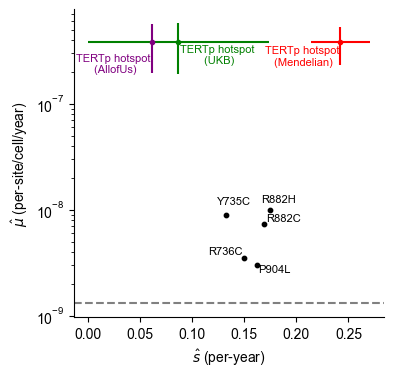

In [13]:
# Provides estimates of specific variants in the population-specific cohort ... 
macgregor_df = pl.read_csv('../data/Table_S3_constant_growth_CH_hotspots.csv')
fig ,ax = plt.subplots(1,1,figsize=(4,4))
test_df = macgregor_df.filter(
    pl.col('Variant').str.contains('DNMT3A')
).with_columns(
    pl.col('Variant').str.split(' ').list[1].alias('Mutation')
).head(5)

texts = []
for (s, mu, l) in zip(test_df['s_per_year'].to_numpy(), test_df['mu_per_cell_per_year'].to_numpy(), test_df['Mutation'].to_numpy()):
    ax.scatter(s, mu, color='black', s=10)
    txt = ax.text(
        s, mu,
        f'{l}',
        color='black',
        zorder=5,
        fontsize=8,
        snap=True,
        ha="center",
        va="bottom",
        clip_on=False,
    )
    texts.append(txt)
    
ax.errorbar(opt_res.x[1], opt_res.x[0], marker='.', 
            xerr=(s_upper - s_lower)/2, yerr=(mu_upper - mu_lower)/2, capsize=0, linestyle='none', label=r'TERTp (Mendelian)', color='red')
txt = ax.text(
    opt_res.x[1], opt_res.x[0]-5e-8,
    'TERTp hotspot\n (Mendelian)',
    color='red',
    zorder=5,
    fontsize=8,
    snap=True,
    ha="right",
    va="center",
    clip_on=True,
)
texts.append(txt)


ax.errorbar(opt_res_AoU.x[1], opt_res_AoU.x[0], marker='.', 
            xerr=(s_AoU_upper - s_AoU_lower), yerr=(mu_AoU_upper - mu_AoU_lower)/2, capsize=0, linestyle='none', label=r'TERTp (AllofUs)', color='purple')

txt = ax.text(
    opt_res_AoU.x[1], opt_res_AoU.x[0]-1e-7,
    'TERTp hotspot\n (AllofUs)',
    color='purple',
    zorder=5,
    fontsize=8,
    snap=True,
    ha="right",
    va="center",
    clip_on=True,
)
texts.append(txt)

ax.errorbar(opt_res_UKB.x[1], opt_res_UKB.x[0], marker='.', 
            xerr=(s_UKB_upper - s_UKB_lower), yerr=(mu_UKB_upper - mu_UKB_lower)/2, capsize=0, linestyle='none', label=r'TERTp (AllofUs)', color='green')

txt = ax.text(
    opt_res_UKB.x[1], opt_res_UKB.x[0]-1e-7,
    'TERTp hotspot\n (UKB)',
    color='green',
    zorder=0,
    fontsize=8,
    snap=True,
    ha="left",
    va="center",
    clip_on=True,
)
texts.append(txt)

ax.axhline(1.3e-9, color='gray', linestyle='--')
ax.set_yscale('log')
ax.set_xlabel(r'$\hat{s}$ (per-year)')
ax.set_ylabel(r'$\hat{\mu}$ (per-site/cell/year)')
adjust_text(texts, ax=ax)
debox(ax)
plt.savefig('../plots/TERTp_mu_s_022426.pdf', dpi=300, bbox_inches='tight')
plt.savefig('../plots/TERTp_mu_s_022426.png', dpi=300, bbox_inches='tight')

In [14]:
np.sum(ds_UKB > 0), ds_UKB.size - np.sum(ds_UKB > 0), ds_UKB.size

(np.int64(61), np.int64(193093), 193154)

In [15]:
np.sum(ds_AoU > 0), ds_AoU.size - np.sum(ds_AoU > 0), ds_AoU.size

(np.int64(126), np.int64(196875), 197001)

In [16]:
# Construct the t-test to formally test for difference in estimates
from scipy.stats import ttest_ind_from_stats

ttest_ind_from_stats(mean1=opt_res.x[1], std1=(s_upper-opt_res.x[1])/2, nobs1=ts_total.size, 
                     mean2=opt_res_AoU.x[1], std2=(s_AoU_upper-opt_res_AoU.x[1])/2, nobs2=ts_AoU.size, )

Ttest_indResult(statistic=np.float64(2850.034106081343), pvalue=np.float64(0.0))

In [17]:
ttest_ind_from_stats(mean1=opt_res.x[0], std1=(mu_upper-opt_res.x[0])/2, nobs1=ts_total.size, 
                     mean2=opt_res_AoU.x[0], std2=(mu_AoU_upper-opt_res_AoU.x[0])/2, nobs2=ts_AoU.size)

Ttest_indResult(statistic=np.float64(0.0), pvalue=np.float64(1.0))

In [18]:
test_df

Variant,n,VAF_threshold,mu_per_cell_per_year,s_per_year,logL,Mutation
str,i64,f64,f64,f64,i64,str
"""DNMT3A R882H""",949,0.036,1.0000e-8,0.175,-9481,"""R882H"""
"""DNMT3A R882C""",606,0.036,7.3000e-9,0.169,-6275,"""R882C"""
"""DNMT3A Y735C""",373,0.02,9.0000e-9,0.132,-3811,"""Y735C"""
"""DNMT3A P904L""",229,0.031,3.0000e-9,0.162,-2596,"""P904L"""
"""DNMT3A R736C""",211,0.027,3.5000e-9,0.15,-2343,"""R736C"""


In [19]:
tertp_df = pl.DataFrame({'Variant': ['TERTp Hotspot', 'TERTp Hotspot', 'TERTp Hotspot'], 
              'n': [np.sum(ds_total > 0), np.sum(ds_AoU > 0), np.sum(ds_UKB > 0)],
              'Dataset': ['shortTL', 'AllofUS', 'UKBiobank (WGS)'],
              'VAF_threshold': [0.001, 0.04, 0.04], 
             'mu_per_cell_per_year': [opt_res.x[0], opt_res_AoU.x[0], opt_res_UKB.x[0]], 
             's_per_year': [opt_res.x[1], opt_res_AoU.x[1], opt_res_UKB.x[1]],
             'mu_95CI': [(mu_lower, mu_upper), (mu_AoU_lower,mu_AoU_upper), (mu_UKB_lower, mu_UKB_upper)],
             's_95CI': [(s_lower, s_upper), (s_AoU_lower, s_AoU_upper), (s_UKB_lower, s_UKB_upper)]})

total_df = pl.concat([macgregor_df.with_columns(pl.lit('UKBiobank (WES)').alias('Dataset')), tertp_df], 
                     how='diagonal', strict=False
                    ).with_columns(pl.col("mu_95CI").cast(pl.List(pl.String)).list.join(';'), 
                                   pl.col("s_95CI").cast(pl.List(pl.String)).list.join(';') )
# total_df.tail()
total_df.write_csv('../plots/TERTp_constant_rate_mle.022426.csv')

In [20]:
tertp_df

Variant,n,Dataset,VAF_threshold,mu_per_cell_per_year,s_per_year,mu_95CI,s_95CI
str,i64,str,f64,f64,f64,list[f64],list[f64]
"""TERTp Hotspot""",31,"""shortTL""",0.001,3.8197e-7,0.242139,"[2.5782e-7, 5.5663e-7]","[0.2168, 0.27348]"
"""TERTp Hotspot""",126,"""AllofUS""",0.04,3.8197e-7,0.061299,"[1.5014e-8, 3.8437e-7]","[0.060186, 0.062372]"
"""TERTp Hotspot""",61,"""UKBiobank (WGS)""",0.04,3.8197e-7,0.086846,"[1.6425e-10, 3.8243e-7]","[1.0000e-9, 0.086865]"
